# Used Car Price Prediction 
#Owner: Jessica Nkosi  
#Purpose:reproduce the data checks, document cleaning decisions, compare baseline models, and tune Extra Trees without using the test set for model selection.


# Used-Car Price Prediction

## 1. Project Objective

The objective of this project is to prepare and analyse a used-car dataset to identify factors that may influence the asking price of a vehicle. The dataset contains information such as the vehicle's brand, model, year, age, distance driven, transmission type, ownership, fuel type and asking price.

The project will begin with data inspection, data cleaning and exploratory data analysis (EDA). These steps will help identify missing values, duplicate records, inconsistent data types and unusual values. Once the data has been assessed and prepared, it can be used to develop and evaluate machine-learning models for predicting used-car asking prices.

The target variable is `AskPrice`. The remaining variables will be assessed to determine their suitability as predictors.

## 2. Initial Questions

- What data-quality issues are present in the dataset?
- How much information is missing from each variable?
- What does the distribution of asking prices look like?
- Which vehicle characteristics may be associated with asking price?
- How should missing, duplicated and inconsistent records be handled before modelling?

In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error
from sklearn.base import clone

print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

pandas: 2.3.3
scikit-learn: 1.7.2


In [109]:
import os
import pandas as pd
import numpy as np

file_path = os.path.expanduser("~/Desktop/used_cars_dataset.csv")

df_raw = pd.read_csv(file_path)

df = df_raw.copy()

print("Dataset loaded successfully")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nOriginal asking prices:")
print(df["AskPrice"].head(10))
print("\nData type:", df["AskPrice"].dtype)

Dataset loaded successfully
Shape: (24575, 11)
Columns: ['Brand', 'model', 'Year', 'Age', 'kmDriven', 'Transmission', 'Owner', 'FuelType', 'PostedDate', 'AdditionInfo', 'AskPrice']

Original asking prices:
0     ₹ 1,95,000
1     ₹ 3,75,000
2     ₹ 1,84,999
3     ₹ 5,65,000
4     ₹ 6,85,000
5    ₹ 13,50,000
6    ₹ 10,25,000
7    ₹ 59,50,000
8     ₹ 6,22,000
9     ₹ 6,49,000
Name: AskPrice, dtype: object

Data type: object


In [110]:
df = pd.read_csv(
    "~/Desktop/used_cars_dataset.csv"
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (24575, 11)


,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,NaN,NaN,2001.0,23.0,"98,000 km",NaN,NaN,Unknown,Nov-24,"Honda City v teck in mint condition, valid gen...","₹ 1,95,000"
1,Toyota,NaN,NaN,15.0,190000.0 km,Manual,NaN,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...","₹ 3,75,000"
2,Volkswagen,NaN,2010.0,NaN,NaN,Manual,first,NaN,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...","₹ 1,84,999"
3,NaN,Swift,2017.0,7.0,NaN,Manual,second,Unknown,NaN,Maruti Suzuki Swift 2017 Diesel Good Condition,"₹ 5,65,000"
4,Maruti Suzuki,NaN,2019.0,5.0,NaN,Automatic,NaN,Unknown,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol","₹ 6,85,000"


In [111]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Number of rows: 24575
Number of columns: 11

Column names:
['Brand', 'model', 'Year', 'Age', 'kmDriven', 'Transmission', 'Owner', 'FuelType', 'PostedDate', 'AdditionInfo', 'AskPrice']

Data types:
Brand            object
model            object
Year            float64
Age             float64
kmDriven         object
Transmission     object
Owner            object
FuelType         object
PostedDate       object
AdditionInfo     object
AskPrice         object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24575 entries, 0 to 24574
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         19306 non-null  object 
 1   model         14144 non-null  object 
 2   Year          19396 non-null  float64
 3   Age           18600 non-null  float64
 4   kmDriven      18344 non-null  object 
 5   Transmission  18653 non-null  object 
 6   Owner         13949 non-null  object 
 7   Fu

In [112]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    "missing_percent", ascending=False
)

display(missing_summary)

,missing_count,missing_percent
Owner,10626,43.24
model,10431,42.45
kmDriven,6231,25.36
PostedDate,6220,25.31
Age,5975,24.31
Transmission,5922,24.10
Brand,5269,21.44
FuelType,5239,21.32
Year,5179,21.07
AdditionInfo,0,0.00


## 3. Initial Dataset Inspection

The dataset contains 24,575 rows and 11 columns. It includes vehicle characteristics and an asking price variable that will be used as the prediction target.

The initial inspection identified several data quality concerns. Some numerical information is stored as text, particularly `AskPrice` and `kmDriven`
Several variables contain missing values, with `Owner` and `model` having the highest missingness in the initial assessment. 
Exact duplicate rows were also identified and require further investigation.
These findings indicate that the dataset needs additional validation and cleaning before statistical analysis and machine learning modelling can be performed reliably.

In [113]:
duplicate_count = df.duplicated().sum()

duplicate_percentage = (
    duplicate_count / len(df)
) * 100

print("Total rows:", len(df))
print("Exact duplicate rows:", duplicate_count)
print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

Total rows: 24575
Exact duplicate rows: 9587
Duplicate percentage: 39.01%


In [114]:
duplicate_examples = df[
    df.duplicated(keep=False)
]

display(duplicate_examples.head(10))

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,NaN,NaN,2001.0,23.0,"98,000 km",NaN,NaN,Unknown,Nov-24,"Honda City v teck in mint condition, valid gen...","₹ 1,95,000"
1,Toyota,NaN,NaN,15.0,190000.0 km,Manual,NaN,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...","₹ 3,75,000"
2,Volkswagen,NaN,2010.0,NaN,NaN,Manual,first,NaN,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...","₹ 1,84,999"
3,NaN,Swift,2017.0,7.0,NaN,Manual,second,Unknown,NaN,Maruti Suzuki Swift 2017 Diesel Good Condition,"₹ 5,65,000"
4,Maruti Suzuki,NaN,2019.0,5.0,NaN,Automatic,NaN,Unknown,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol","₹ 6,85,000"
5,BMW,NaN,2014.0,NaN,"83,000 km",NaN,first,Unknown,Nov-24,"BMW X3 2.0 XDRIVE 20D, 2014, Diesel","₹ 13,50,000"
6,Unknown,NaN,NaN,10.0,"168,000 km",Manual,second,Diesel,Nov-24,"Toyota Innova 2.5 VX 8 Seater BS IV, 2014, Diesel","₹ 10,25,000"
7,BMW,NaN,2019.0,5.0,NaN,Automatic,NaN,Diesel,Nov-24,"BMW 5 Series 3.0 530D M Sport, 2019, Diesel","₹ 59,50,000"
8,Maruti Suzuki,NaN,9999.0,NaN,"33,759 km",Manual,NaN,Petrol,Nov-24,"Maruti Suzuki Dzire 1.2 VXI, 2020, Petrol","₹ 6,22,000"
9,Ford,Ecosport,9999.0,NaN,NaN,Manual,second,NaN,NaN,"Ford Ecosport 1.5 Ti VCT MT Titanium BE, 2017,...","₹ 6,49,000"


In [115]:
print(df.columns.tolist())

['Brand', 'model', 'Year', 'Age', 'kmDriven', 'Transmission', 'Owner', 'FuelType', 'PostedDate', 'AdditionInfo', 'AskPrice']


In [116]:
df_original = df.copy()

df = df.drop_duplicates().copy()

print("Shape after removing duplicates:", df.shape)
print("Duplicates remaining:", df.duplicated().sum())

Shape after removing duplicates: (14988, 11)
Duplicates remaining: 0


## 4 Duplicate Record Investigation

The initial assessment identified 9,587 exact duplicate rows, representing approximately 39.0% of the original dataset. Exact duplicates are records in which all available column values match.

Duplicate records can affect the analysis because repeated observations may give particular records more influence during model training. However, identical rows do not necessarily confirm that the underlying listings are the same, particularly when the dataset does not contain a unique listing identifier.

For the initial modelling dataset, exact duplicate rows will be removed under the assumption that they represent redundant copies. This decision will be documented as a limitation, and the dataset shape and remaining duplicate count will be checked after removal.

In [117]:
df["kmDriven"] = (
    df["kmDriven"]
    .astype("string")
    .str.replace(",", "", regex=False)
    .str.replace(r"(?i)\s*km\b", "", regex=True)
    .str.strip()
)

df["kmDriven"] = pd.to_numeric(
    df["kmDriven"],
    errors="coerce"
)

In [118]:
print(df[["AskPrice", "kmDriven"]].dtypes)

display(df[["AskPrice", "kmDriven"]].head(10))

print("\nMissing values after conversion:")
display(df[["AskPrice", "kmDriven"]].isna().sum())

AskPrice     object
kmDriven    Float64
dtype: object


,AskPrice,kmDriven
0,"₹ 1,95,000",98000.0
1,"₹ 3,75,000",190000.0
2,"₹ 1,84,999",<NA>
3,"₹ 5,65,000",<NA>
4,"₹ 6,85,000",<NA>
5,"₹ 13,50,000",83000.0
6,"₹ 10,25,000",168000.0
7,"₹ 59,50,000",<NA>
8,"₹ 6,22,000",33759.0
9,"₹ 6,49,000",<NA>



Missing values after conversion:


AskPrice       0
kmDriven    3148
dtype: int64

In [119]:
print("Missing asking prices:", df["AskPrice"].isna().sum())
print("Total records:", len(df))

display(df[["Brand", "model", "AskPrice"]].head(10))

Missing asking prices: 0
Total records: 14988


,Brand,model,AskPrice
0,NaN,NaN,"₹ 1,95,000"
1,Toyota,NaN,"₹ 3,75,000"
2,Volkswagen,NaN,"₹ 1,84,999"
3,NaN,Swift,"₹ 5,65,000"
4,Maruti Suzuki,NaN,"₹ 6,85,000"
5,BMW,NaN,"₹ 13,50,000"
6,Unknown,NaN,"₹ 10,25,000"
7,BMW,NaN,"₹ 59,50,000"
8,Maruti Suzuki,NaN,"₹ 6,22,000"
9,Ford,Ecosport,"₹ 6,49,000"


In [120]:
df["AskPrice"] = (
    df["AskPrice"]
    .astype("string")
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df["AskPrice"] = pd.to_numeric(
    df["AskPrice"],
    errors="coerce"
)

print("Missing AskPrice:", df["AskPrice"].isna().sum())
print("AskPrice data type:", df["AskPrice"].dtype)

Missing AskPrice: 0
AskPrice data type: Int64


In [121]:
df = df.drop_duplicates().copy()

print("Dataset shape:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())
print("Missing AskPrice:", df["AskPrice"].isna().sum())

Dataset shape: (14988, 11)
Remaining duplicates: 0
Missing AskPrice: 0


## 5. Data Type Correction

The initial inspection showed that `AskPrice` and `kmDriven` were stored as text rather than numerical variables. The asking-price column contained currency symbols and separators, while the mileage column contained commas and the unit "km".

These characters were removed before converting both columns to numeric data types. Values that could not be converted were treated as missing so that they could be investigated. The conversion was then verified by checking the resulting data types and missing-value counts.

This step is necessary because numerical analysis and price prediction require these variables to be represented as numbers rather than unprocessed text.

In [122]:
display(
    df[["Year", "Age"]].describe()
)

,Year,Age
count,12391.000000,11995.000000
mean,3666.820192,7.692705
std,3233.002118,4.404578
min,1900.000000,0.000000
25%,2015.000000,5.000000
50%,2018.000000,7.000000
75%,2022.000000,10.000000
max,9999.000000,124.000000


In [123]:
display(
    df.loc[
        (df["Year"] < 1980) | (df["Year"] > 2026),
        ["Brand", "model", "Year", "Age", "PostedDate", "AskPrice"]
    ].head(20)
)

,Brand,model,Year,Age,PostedDate,AskPrice
8,Maruti Suzuki,NaN,9999.0,NaN,Nov-24,622000
9,Ford,Ecosport,9999.0,NaN,NaN,649000
13,Unknown,NaN,9999.0,17.0,Nov-24,201350
17,Maruti Suzuki,NaN,9999.0,8.0,Nov-24,785000
23,Audi,A3,9999.0,9.0,Nov-24,1050000
25,NaN,Hector,9999.0,5.0,Oct-24,1250000
29,Toyota,NaN,9999.0,1.0,Nov-24,4195000
31,Toyota,NaN,9999.0,13.0,NaN,490000
34,Unknown,Ertiga,9999.0,NaN,Nov-24,749000
38,Mercedes-Benz,NaN,9999.0,NaN,Oct-24,4200000


In [124]:
display(
    df.loc[
        (df["Age"] < 0) | (df["Age"] > 40),
        ["Brand", "model", "Year", "Age", "PostedDate", "AskPrice"]
    ].head(20)
)

,Brand,model,Year,Age,PostedDate,AskPrice
20842,Maruti Suzuki,Wagon-R,1931.0,93.0,Nov-24,349000
20974,Renault,Triber,1900.0,124.0,Dec-24,440000
21040,Mahindra,Jeep,1978.0,46.0,Nov-24,200000
22127,Maruti Suzuki,Swift,1920.0,104.0,Nov-24,519000


In [125]:
print(df["PostedDate"].value_counts(dropna=False).head(20))

PostedDate
Nov-24    10425
NaN        3121
Dec-24      764
Oct-24      472
Sep-24      101
Aug-24       58
Jul-24       21
Jun-24       12
Apr-24        6
Dec-23        3
May-24        2
Jan-24        2
Mar-24        1
Name: count, dtype: int64


# 6. Validation of Year, Age and Listing Date

The `Year` and `Age` variables describe related aspects of a vehicle, but they may have been recorded using different reference dates or data sources. Implausible values and inconsistencies between these variables could affect the reliability of the analysis.

The next step is to inspect unusual values and compare them with the available listing-date information. Values will not be removed merely because they fall outside an arbitrary range. Any decision to correct, retain or treat a value as missing will depend on the evidence available.

The limitation is that the exact method used to calculate the original `Age` variable has not yet been established.

In [126]:
display(
    df["AskPrice"].describe(
        percentiles=[
            0.25, 0.50, 0.75, 0.90, 0.95, 0.99
        ]
    )
)

count           14988.0
mean      996884.795703
std      1586834.596681
min             15000.0
25%            349000.0
50%            570000.0
75%           1025000.0
90%           1995000.0
95%           3250000.0
99%           7500000.0
max          42500000.0
Name: AskPrice, dtype: Float64

In [127]:
print(df["AskPrice"].dtype)
print(df["AskPrice"].head())

Int64
0    195000
1    375000
2    184999
3    565000
4    685000
Name: AskPrice, dtype: Int64


In [128]:
df["AskPrice"] = pd.to_numeric(
    df["AskPrice"],
    errors="coerce"
).astype("float64")

In [129]:
print("Missing AskPrice values:", df["AskPrice"].isna().sum())

Missing AskPrice values: 0


In [130]:
print("Data type:", df["AskPrice"].dtype)

print("\nFirst 20 asking prices:")
print(df["AskPrice"].head(20))

print("\nNumber of unique values:")
print(df["AskPrice"].nunique())

print("\nNon-missing values:")
print(df["AskPrice"].dropna().head(20))

Data type: float64

First 20 asking prices:
0       195000.0
1       375000.0
2       184999.0
3       565000.0
4       685000.0
5      1350000.0
6      1025000.0
7      5950000.0
8       622000.0
9       649000.0
10      395000.0
11     2900000.0
12      240000.0
13      201350.0
14    11800000.0
15      330000.0
16     1045000.0
17      785000.0
18      555000.0
19     1500000.0
Name: AskPrice, dtype: float64

Number of unique values:
1616

Non-missing values:
0       195000.0
1       375000.0
2       184999.0
3       565000.0
4       685000.0
5      1350000.0
6      1025000.0
7      5950000.0
8       622000.0
9       649000.0
10      395000.0
11     2900000.0
12      240000.0
13      201350.0
14    11800000.0
15      330000.0
16     1045000.0
17      785000.0
18      555000.0
19     1500000.0
Name: AskPrice, dtype: float64


In [131]:
price_columns = [
    "Brand", "model", "Year", "kmDriven", "AskPrice"
]

display(
    df.nsmallest(10, "AskPrice")[price_columns]
)

display(
    df.nlargest(10, "AskPrice")[price_columns]
)

,Brand,model,Year,kmDriven,AskPrice
1751,Mahindra,Marshal,9999.0,<NA>,15000.0
19934,Maruti Suzuki,Brezza,2023.0,<NA>,15000.0
23167,BMW,5 Series,2014.0,90000.0,15000.0
24024,Renault,Duster,2013.0,80000.0,15000.0
23503,Maruti Suzuki,Alto-K10,2021.0,12.0,18000.0
3034,Maruti Suzuki,NaN,9999.0,9000.0,18500.0
271,Maruti Suzuki,Alto-800,2006.0,<NA>,20000.0
24497,Maruti Suzuki,Wagon-R-1-0,2024.0,55500.0,20000.0
21522,Mahindra,Thar Roxx,2024.0,0.0,21000.0
7242,Maruti Suzuki,Zen-Estilo,1998.0,<NA>,27000.0


,Brand,model,Year,kmDriven,AskPrice
3331,Rolls-Royce,Phantom Series II,9999.0,<NA>,42500000.0
22267,Lamborghini,Urus,2021.0,26000.0,39000000.0
22868,Mercedes-Benz,G Class,2023.0,6000.0,34800000.0
19873,Mercedes-Benz,G Class,2024.0,3500.0,30500000.0
962,Lexus,NaN,NaN,<NA>,27750000.0
331,Unknown,NaN,9999.0,25700.0,26400000.0
811,Unknown,NaN,2019.0,<NA>,26000000.0
5767,Mercedes-Benz,NaN,2019.0,<NA>,24900000.0
1187,NaN,Land Cruiser,2023.0,15000.0,24700000.0
7435,Unknown,NaN,2024.0,1400.0,24500000.0


In [132]:
invalid_price_rows = df[
    df["AskPrice"].isna() | (df["AskPrice"] <= 0)
]

print("Invalid or missing prices:", len(invalid_price_rows))

display(invalid_price_rows.head(10))

Invalid or missing prices: 0


,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice


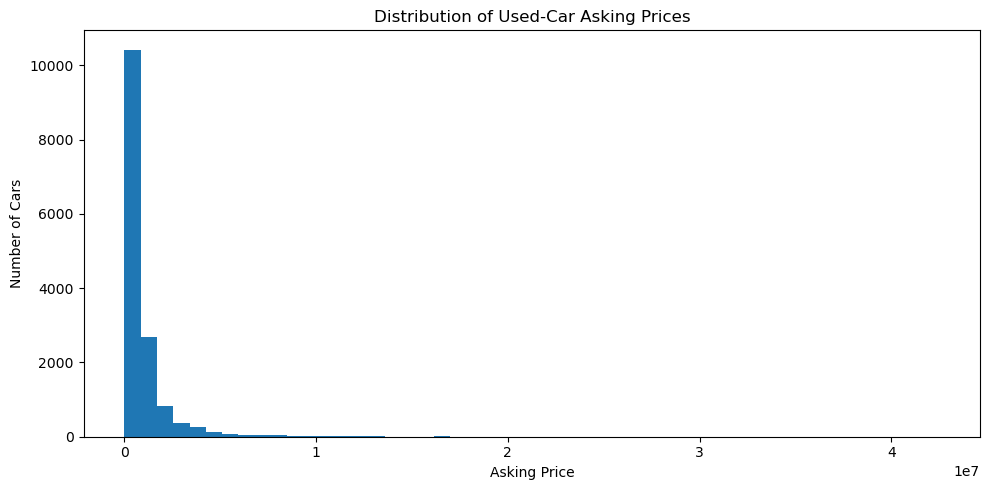

In [133]:
prices = df.loc[df["AskPrice"] > 0, "AskPrice"]

plt.figure(figsize=(10, 5))
plt.hist(prices, bins=50)
plt.xlabel("Asking Price")
plt.ylabel("Number of Cars")
plt.title("Distribution of Used-Car Asking Prices")
plt.tight_layout()
plt.show()

### Interpretation of the Asking-Price Distribution

The histogram indicates that the asking-price distribution is positively skewed (right-skewed). Most observations are concentrated at the lower end of the price range, while a smaller number of observations extend towards substantially higher prices.

This suggests that the dataset contains considerable variation in asking prices and that extreme values may influence statistical summaries such as the mean. However, the histogram alone does not establish whether the highest prices are data-entry errors or legitimate prices for more expensive vehicles.

The next step is to examine descriptive statistics and inspect the lowest and highest asking-price observations. This will help determine whether any values require correction or further investigation before model development.

### 7.1 Descriptive Statistics of Asking Prices

After visualising the asking-price distribution, descriptive statistics are used to examine the numerical characteristics of the target variable. This includes the average, median, minimum, maximum and quartiles.

The purpose is to understand the range and spread of vehicle prices and identify whether extreme values may influence the overall distribution.

In [134]:
display(
    df["AskPrice"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

count    1.498800e+04
mean     9.968848e+05
std      1.586835e+06
min      1.500000e+04
25%      3.490000e+05
50%      5.700000e+05
75%      1.025000e+06
90%      1.995000e+06
95%      3.250000e+06
99%      7.500000e+06
max      4.250000e+07
Name: AskPrice, dtype: float64

In [135]:

df["AskPrice"] = (
    df["AskPrice"]
    .astype("string")
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df["AskPrice"] = pd.to_numeric(
    df["AskPrice"],
    errors="coerce"
)

In [136]:
print("Data type:", df["AskPrice"].dtype)

display(df["AskPrice"].describe())

Data type: Float64


count           14988.0
mean      996884.795703
std      1586834.596681
min             15000.0
25%            349000.0
50%            570000.0
75%           1025000.0
max          42500000.0
Name: AskPrice, dtype: Float64

Reassessment of duplicate records

Following the initial analysis of the asking-price distribution, the dataset will be reassessed for exact duplicate records. This is important because repeated observations can influence descriptive statistics and may give certain records disproportionate representation during model training.

The original inspection identified 9,587 exact duplicate rows. Since the dataset was reloaded, the duplicate count will be checked again before proceeding. Records identified as redundant copies will be removed from the working dataset, while the original dataset will be preserved for reference.

The absence of a unique listing identifier is recognised as a limitation because identical records cannot automatically be confirmed as the same real-world listing.

In [137]:
print("Dataset shape before duplicate removal:", df.shape)
print("Exact duplicate rows:", df.duplicated().sum())

Dataset shape before duplicate removal: (14988, 11)
Exact duplicate rows: 0


In [138]:
df = df.drop_duplicates().copy()

print("Dataset shape after duplicate removal:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Dataset shape after duplicate removal: (14988, 11)
Remaining duplicates: 0


Descriptive Statistics After Duplicate Removal

After removing the identified exact duplicate records, descriptive statistics will be recalculated to establish the distribution of asking prices in the updated dataset.

This step is necessary because duplicate records may influence the mean, median and other statistical measures. The updated statistics will provide a more representative summary of the working dataset and will be used to guide the investigation of unusually low and high asking prices.

In [139]:
display(
    df["AskPrice"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

count           14988.0
mean      996884.795703
std      1586834.596681
min             15000.0
25%            349000.0
50%            570000.0
75%           1025000.0
90%           1995000.0
95%           3250000.0
99%           7500000.0
max          42500000.0
Name: AskPrice, dtype: Float64

 Investigation of Extreme Asking Prices

The asking-price distribution indicates substantial variation in vehicle prices. To investigate this further, the lowest and highest asking-price observations will be examined.

This analysis aims to identify potentially incorrect values and determine whether extreme prices represent legitimate differences between vehicles. High-priced vehicles will not automatically be classified as errors because some brands and models may legitimately have substantially higher market values.

The investigation will consider the available vehicle information, including brand, model, year, age and distance driven.

In [140]:
price_columns = [
    "Brand",
    "model",
    "Year",
    "Age",
    "kmDriven",
    "AskPrice"
]

display(
    df.nsmallest(10, "AskPrice")[price_columns]
)

,Brand,model,Year,Age,kmDriven,AskPrice
1751,Mahindra,Marshal,9999.0,24.0,<NA>,15000.0
19934,Maruti Suzuki,Brezza,2023.0,1.0,<NA>,15000.0
23167,BMW,5 Series,2014.0,10.0,90000.0,15000.0
24024,Renault,Duster,2013.0,11.0,80000.0,15000.0
23503,Maruti Suzuki,Alto-K10,2021.0,3.0,12.0,18000.0
3034,Maruti Suzuki,NaN,9999.0,0.0,9000.0,18500.0
271,Maruti Suzuki,Alto-800,2006.0,NaN,<NA>,20000.0
24497,Maruti Suzuki,Wagon-R-1-0,2024.0,0.0,55500.0,20000.0
21522,Mahindra,Thar Roxx,2024.0,0.0,0.0,21000.0
7242,Maruti Suzuki,Zen-Estilo,1998.0,26.0,<NA>,27000.0


In [141]:
display(
    df.nlargest(10, "AskPrice")[price_columns]
)

,Brand,model,Year,Age,kmDriven,AskPrice
3331,Rolls-Royce,Phantom Series II,9999.0,NaN,<NA>,42500000.0
22267,Lamborghini,Urus,2021.0,3.0,26000.0,39000000.0
22868,Mercedes-Benz,G Class,2023.0,1.0,6000.0,34800000.0
19873,Mercedes-Benz,G Class,2024.0,0.0,3500.0,30500000.0
962,Lexus,NaN,NaN,0.0,<NA>,27750000.0
331,Unknown,NaN,9999.0,8.0,25700.0,26400000.0
811,Unknown,NaN,2019.0,5.0,<NA>,26000000.0
5767,Mercedes-Benz,NaN,2019.0,5.0,<NA>,24900000.0
1187,NaN,Land Cruiser,2023.0,1.0,15000.0,24700000.0
7435,Unknown,NaN,2024.0,0.0,1400.0,24500000.0


In [142]:
print("Missing prices:", df["AskPrice"].isna().sum())

print(
    "Zero or negative prices:",
    (df["AskPrice"] <= 0).sum()
)

Missing prices: 0
Zero or negative prices: 0


 Investigation of Vehicle Age and Manufacturing Year

The dataset contains both Year and Age, which provide related information about the vehicle. These variables will be examined to identify missing, unusual or potentially inconsistent values.

The PostedDate variable will also be considered because it may provide context for understanding how the age of a vehicle was recorded.

The purpose of this investigation is to establish whether these variables are sufficiently reliable for use in the prediction model. Unusual values will be investigated before any corrections or exclusions are made.

In [143]:
display(
    df[["Year", "Age"]].describe()
)

,Year,Age
count,12391.000000,11995.000000
mean,3666.820192,7.692705
std,3233.002118,4.404578
min,1900.000000,0.000000
25%,2015.000000,5.000000
50%,2018.000000,7.000000
75%,2022.000000,10.000000
max,9999.000000,124.000000


In [144]:
display(
    df.loc[
        (df["Year"] < 1980) | (df["Year"] > 2026),
        ["Brand", "model", "Year", "Age", "PostedDate", "AskPrice"]
    ].head(20)
)

,Brand,model,Year,Age,PostedDate,AskPrice
8,Maruti Suzuki,NaN,9999.0,NaN,Nov-24,622000.0
9,Ford,Ecosport,9999.0,NaN,NaN,649000.0
13,Unknown,NaN,9999.0,17.0,Nov-24,201350.0
17,Maruti Suzuki,NaN,9999.0,8.0,Nov-24,785000.0
23,Audi,A3,9999.0,9.0,Nov-24,1050000.0
25,NaN,Hector,9999.0,5.0,Oct-24,1250000.0
29,Toyota,NaN,9999.0,1.0,Nov-24,4195000.0
31,Toyota,NaN,9999.0,13.0,NaN,490000.0
34,Unknown,Ertiga,9999.0,NaN,Nov-24,749000.0
38,Mercedes-Benz,NaN,9999.0,NaN,Oct-24,4200000.0


In [145]:
display(
    df.loc[
        (df["Age"] < 0) | (df["Age"] > 40),
        ["Brand", "model", "Year", "Age", "PostedDate", "AskPrice"]
    ].head(20)
)

,Brand,model,Year,Age,PostedDate,AskPrice
20842,Maruti Suzuki,Wagon-R,1931.0,93.0,Nov-24,349000.0
20974,Renault,Triber,1900.0,124.0,Dec-24,440000.0
21040,Mahindra,Jeep,1978.0,46.0,Nov-24,200000.0
22127,Maruti Suzuki,Swift,1920.0,104.0,Nov-24,519000.0


In [146]:
display(
    df["PostedDate"].value_counts(dropna=False).head(20)
)

PostedDate
Nov-24    10425
NaN        3121
Dec-24      764
Oct-24      472
Sep-24      101
Aug-24       58
Jul-24       21
Jun-24       12
Apr-24        6
Dec-23        3
May-24        2
Jan-24        2
Mar-24        1
Name: count, dtype: int64

## Analysis of PostedDate

The `PostedDate` variable represents the month and year when a vehicle listing was posted. The frequency distribution shows that most listings were posted in November 2024, with 10,425 records. A further 3,121 records have missing dates.

The remaining records are concentrated mainly between October and December 2024, while only a small number of listings have dates from earlier months.

This uneven distribution suggests that the dataset contains listings concentrated within a relatively short period. Missing dates will be retained for further consideration rather than automatically replaced, as assigning dates without supporting information could introduce inaccuracies.

The predictive usefulness of this variable will be evaluated during the modelling stage.

In [147]:
print("Missing PostedDate values:")
print(df["PostedDate"].isna().sum())

print("\nPercentage missing:")
print(round(df["PostedDate"].isna().mean() * 100, 2), "%")

print("\nUnique date values:")
print(df["PostedDate"].dropna().unique())

Missing PostedDate values:
3121

Percentage missing:
20.82 %

Unique date values:
['Nov-24' 'Jul-24' 'Oct-24' 'Aug-24' 'Sep-24' 'May-24' 'Jun-24' 'Apr-24'
 'Jan-24' 'Dec-23' 'Mar-24' 'Dec-24']


# Findings and Data Quality Assessment: PostedDate

The `PostedDate` variable contains information about when each vehicle listing was posted. The analysis identified 3,121 missing values, representing 20.82% of the dataset.

Among the available records, November 2024 is the dominant posting month, accounting for 10,425 listings. The recorded dates range from December 2023 to December 2024 and follow a consistent month-year format.

The distribution is heavily concentrated in November 2024. Therefore, the variable may have limited usefulness for analysing posting trends across the entire period. Missing values will not be replaced with an assumed date, as this could introduce misleading information.

The variable will be retained for consideration during feature selection and model development.

#Analysis of Categorical Variables

Categorical variables represent descriptive characteristics of the vehicles, such as their manufacturer, model, transmission type, ownership history and fuel type.

These variables need to be examined to understand the different categories present in the dataset, identify inconsistent naming conventions, and assess whether there are unusual or frequently occurring values.

This analysis will help determine the appropriate preprocessing techniques before developing the machine learning models.

In [148]:
categorical_columns = [
    "Brand",
    "model",
    "Transmission",
    "Owner",
    "FuelType"
]

for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].value_counts(dropna=False).head(20))
    print("Number of unique values:", df[column].nunique())


Brand
Brand
Maruti Suzuki    3150
NaN              2641
Unknown          2574
Hyundai          1660
Honda             821
Toyota            717
Mahindra          434
Mercedes-Benz     403
Tata              383
Volkswagen        315
BMW               295
Ford              248
Renault           243
Audi              213
Skoda             164
Kia               146
Chevrolet          81
Nissan             76
MG                 69
Jeep               61
Name: count, dtype: int64
Number of unique values: 41

model
model
NaN              5233
Wagon-R           446
City              372
Ertiga            297
Swift             272
Swift-Dzire       252
Celerio           233
i10               218
Creta             217
Grand i10         211
Eeco              210
Baleno            173
Verna             160
i20               150
Innova Crysta     146
Alto-800          145
Polo              141
Fortuner          139
Amaze             132
XUV500            118
Name: count, dtype: int64
Number of uniq

# Checking for Inconsistent Categorical Entries

After examining the frequency distributions, the next step is to investigate whether categorical values have been recorded consistently.

Differences in capitalisation and unnecessary spaces can cause the same category to be treated as multiple distinct values. This can affect the quality of the data and the preprocessing required for machine learning.

The categorical variables will therefore be checked for inconsistent formatting before any standardisation is applied.

In [149]:
for column in categorical_columns:
    print(f"\n{column}")
    print("Values with leading or trailing spaces:")
    print(
        df[column]
        .dropna()
        .loc[lambda x: x != x.str.strip()]
        .value_counts()
    )

    print("\nAll distinct values:")
    print(sorted(df[column].dropna().unique()))


Brand
Values with leading or trailing spaces:
Series([], Name: count, dtype: int64)

All distinct values:
['Ambassador', 'Audi', 'BMW', 'Bajaj', 'Bentley', 'Chevrolet', 'Citroen', 'Datsun', 'Fiat', 'Force', 'Ford', 'Honda', 'Hummer', 'Hyundai', 'Isuzu', 'Jaguar', 'Jeep', 'Kia', 'Lamborghini', 'Land Rover', 'Lexus', 'MG', 'Mahindra', 'Maruti Suzuki', 'Maserati', 'Mercedes-Benz', 'Mini', 'Mitsubishi', 'Nissan', 'Opel', 'Porsche', 'Renault', 'Rolls-Royce', 'Skoda', 'Ssangyong', 'Tata', 'Toyota', 'Toyota Land', 'Unknown', 'Volkswagen', 'Volvo']

model
Values with leading or trailing spaces:
model
Fronx     6
Punch     5
Name: count, dtype: int64

All distinct values:
['1 Series', '1000', '2 Series', '2.8 Legender 4X2', '2.9 Sportback', '3 DOOR', '3 Series', '3 Series GT', '3 Series Gran Limousine', '5 Series', '5 Series Gt', '6 Series', '6 Series GT', '7 Series', '718', '718 CAYMAN', '800', 'A Class', 'A-Class Limousine', 'A-Star', 'A3', 'A3 Cabriolet', 'A4', 'A5', 'A6', 'A8', 'A8 L', 'AM

# Findings: Categorical Formatting and Consistency

The inspection of categorical variables identified inconsistencies mainly within the `model` and `FuelType` columns.

The Brand, Transmission and Owner  variables did not show leading or trailing whitespace issues. However, the `Brand` variable contains an explicit Unknown category, which will require separate consideration during preprocessing.

The model variable contains 403 unique categories. Some entries have unnecessary trailing spaces, while other entries appear to represent the same vehicle models using different capitalisation or separators. These inconsistencies may cause identical or closely related vehicle models to be treated as separate categories during machine learning.

The `FuelType` variable also contains a capitalisation inconsistency, with `hybrid` and `Hybrid` represented differently. The `Hybrid/CNG` category will remain separate because it represents a distinct recorded category.

These findings indicate that selected formatting corrections are necessary before modelling. However, potentially equivalent vehicle model names will require further investigation before being merged.

In [150]:
df["model"] = df["model"].str.strip()

df["FuelType"] = df["FuelType"].str.strip()

df["FuelType"] = df["FuelType"].replace({
    "hybrid": "Hybrid"
})

In [151]:
print(df["model"].value_counts().head(10))

print("\nFuelType categories:")
print(df["FuelType"].value_counts(dropna=False))

print("\nRemaining model spacing issues:")
print(
    df["model"]
    .dropna()
    .loc[lambda x: x != x.str.strip()]
    .value_counts()
)

model
Wagon-R        446
City           372
Ertiga         297
Swift          272
Swift-Dzire    252
Celerio        233
i10            218
Creta          217
Grand i10      211
Eeco           210
Name: count, dtype: int64

FuelType categories:
FuelType
Petrol        3713
Diesel        3172
NaN           2629
Unknown       2608
Hybrid        1997
Hybrid/CNG     869
Name: count, dtype: int64

Remaining model spacing issues:
Series([], Name: count, dtype: int64)


In [152]:
print(
    df.loc[
        df["Brand"] == "Toyota Land",
        ["Brand", "model", "Year", "AskPrice"]
    ].head(20)
)

print("\nFrequency:")
print((df["Brand"] == "Toyota Land").sum())

             Brand          model    Year    AskPrice
20588  Toyota Land        Cruiser  2013.0   8200000.0
21116  Toyota Land        Cruiser  2017.0  16500000.0
21906  Toyota Land  Cruiser Prado  2012.0   3200000.0
23927  Toyota Land        Cruiser  2008.0   6000000.0

Frequency:
4


# Investigation of the Toyota Land Category

Further investigation of the `Brand` variable identified four records categorised as `Toyota Land`.

An examination of the associated vehicle models showed that these records refer to Land Cruiser and Land Cruiser Prado vehicles. This indicates that the brand name was incorrectly separated during data collection or preparation.

Since these vehicles belong to the Toyota brand, the four records will be corrected by changing `Toyota Land` to `Toyota`. The associated model descriptions will be retained because they provide additional information about the specific vehicles.

In [153]:
df.loc[df["Brand"] == "Toyota Land", "Brand"] = "Toyota"

In [154]:
print(df["Brand"].value_counts().head(10))

print("\nRemaining Toyota Land records:")
print((df["Brand"] == "Toyota Land").sum())

Brand
Maruti Suzuki    3150
Unknown          2574
Hyundai          1660
Honda             821
Toyota            721
Mahindra          434
Mercedes-Benz     403
Tata              383
Volkswagen        315
BMW               295
Name: count, dtype: int64

Remaining Toyota Land records:
0


In [155]:
print("Brand categories:", df["Brand"].nunique())
print("Model categories:", df["model"].nunique())
print("FuelType categories:", df["FuelType"].nunique())

print("\nMissing values:")
print(df[categorical_columns].isna().sum())

Brand categories: 40
Model categories: 402
FuelType categories: 5

Missing values:
Brand           2641
model           5233
Transmission    2970
Owner           5329
FuelType        2629
dtype: int64


# Summary of Categorical Variable Assessment

The categorical variable analysis identified differences in the number of unique categories, formatting inconsistencies and missing values.

The `Brand` variable contains 40 unique categories, `model` contains 402, while `Transmission`, `Owner` and `FuelType` contain relatively fewer categories.

Formatting corrections were applied to remove unnecessary spaces in vehicle model names and standardise the capitalisation of fuel types. Four records incorrectly categorised as `Toyota Land` were corrected to `Toyota` after examining their associated vehicle models.

The missing-value assessment revealed that `Owner` has the highest proportion of missing values (35.56%), followed by `model` (34.91%). The remaining categorical variables also contain missing observations.

The records will be retained rather than removed through complete-case deletion. Missing categorical values will be addressed during the machine learning preprocessing stage.

# Overall Missing Value Assessment

After examining the individual variables, an overall missing-value assessment is necessary to determine the extent of incomplete information in the dataset.

This assessment will identify which variables contain missing observations, the proportion of missing values in each column, and whether certain variables require special attention before model development.

The findings will guide decisions on data retention and missing-value treatment.

In [156]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Percentage Missing": df.isna().mean() * 100
})

missing_summary = missing_summary.sort_values(
    by="Percentage Missing",
    ascending=False
)

print(missing_summary.round(2))

              Missing Values  Percentage Missing
Owner                   5329               35.56
model                   5233               34.91
kmDriven                3148               21.00
PostedDate              3121               20.82
Age                     2993               19.97
Transmission            2970               19.82
Brand                   2641               17.62
FuelType                2629               17.54
Year                    2597               17.33
AdditionInfo               0                0.00
AskPrice                   0                0.00


# Overall Missing-Value Findings

The overall missing-value assessment revealed that several variables contain incomplete observations.

The highest proportions of missing values were identified in the `Owner` variable (35.56%) and the `model` variable (34.91%). Numerical variables such as `kmDriven`, `Age` and `Year` also contain missing observations.

The `PostedDate` variable has 20.82% missing values, while `Transmission`, `Brand` and `FuelType` have missing-value percentages ranging between approximately 17% and 20%.

The `AdditionInfo` and `AskPrice` variables contain no missing values.

Since the target variable, `AskPrice`, is complete, the dataset can be retained for the prediction task without removing records due to missing target values. Missing predictor values will be handled using appropriate imputation techniques during the preprocessing stage. This approach will help preserve available information while preventing unnecessary data loss.§m

# Investigating the Relationship Between Year and Age

The dataset contains both `Year` and `Age`, which describe related aspects of a vehicle's manufacturing and usage history.

Before applying missing-value treatment, it is necessary to investigate whether the two variables are consistent. This will help identify possible data-entry errors and determine whether one variable can provide useful information when assessing missing values in the other.

In [157]:
print("Year and Age summary:")
print(df[["Year", "Age"]].describe())

print("\nCorrelation between Year and Age:")
print(df[["Year", "Age"]].corr())

print("\nRecords where both Year and Age are available:")
print(df[["Year", "Age"]].dropna().head(15))

Year and Age summary:
               Year           Age
count  12391.000000  11995.000000
mean    3666.820192      7.692705
std     3233.002118      4.404578
min     1900.000000      0.000000
25%     2015.000000      5.000000
50%     2018.000000      7.000000
75%     2022.000000     10.000000
max     9999.000000    124.000000

Correlation between Year and Age:
         Year      Age
Year  1.00000 -0.00432
Age  -0.00432  1.00000

Records where both Year and Age are available:
      Year   Age
0   2001.0  23.0
3   2017.0   7.0
4   2019.0   5.0
7   2019.0   5.0
13  9999.0  17.0
15  2018.0   6.0
17  9999.0   8.0
18  2017.0   7.0
23  9999.0   9.0
25  9999.0   5.0
28  2018.0   6.0
29  9999.0   1.0
30  2017.0   7.0
31  9999.0  13.0
35  2023.0   1.0


# Investigation of Invalid Year and Age Values

The descriptive statistics identified potentially invalid observations in the `Year` and `Age` variables. The manufacturing year includes values such as 9999, while the vehicle age includes an unusually high value of 124 years.

These observations may represent placeholder values or data-entry errors. Further investigation is required to establish their frequency and examine the associated vehicle records before deciding how to handle them.

In [158]:
print("Year values below 1980:")
print(df.loc[df["Year"] < 1980, "Year"].value_counts().sort_index())

print("\nYear values above 2024:")
print(df.loc[df["Year"] > 2024, "Year"].value_counts().sort_index())

Year values below 1980:
Year
1900.0    1
1920.0    1
1931.0    1
1978.0    1
Name: count, dtype: int64

Year values above 2024:
Year
9999.0    2562
Name: count, dtype: int64


In [159]:
print("Age values above 30:")
print(df.loc[df["Age"] > 30, "Age"].value_counts().sort_index())

print("\nAge values below zero:")
print(df.loc[df["Age"] < 0, "Age"].value_counts().sort_index())

Age values above 30:
Age
34.0     1
46.0     1
93.0     1
104.0    1
124.0    1
Name: count, dtype: int64

Age values below zero:
Series([], Name: count, dtype: int64)


In [160]:
suspicious_records = df.loc[
    (df["Year"] < 1980) |
    (df["Year"] > 2024) |
    (df["Age"] > 30) |
    (df["Age"] < 0),
    ["Brand", "model", "Year", "Age", "PostedDate", "AskPrice"]
]

print(suspicious_records.head(30))
print("\nTotal suspicious records:", len(suspicious_records))

             Brand      model    Year   Age PostedDate   AskPrice
8    Maruti Suzuki        NaN  9999.0   NaN     Nov-24   622000.0
9             Ford   Ecosport  9999.0   NaN        NaN   649000.0
13         Unknown        NaN  9999.0  17.0     Nov-24   201350.0
17   Maruti Suzuki        NaN  9999.0   8.0     Nov-24   785000.0
23            Audi         A3  9999.0   9.0     Nov-24  1050000.0
25             NaN     Hector  9999.0   5.0     Oct-24  1250000.0
29          Toyota        NaN  9999.0   1.0     Nov-24  4195000.0
31          Toyota        NaN  9999.0  13.0        NaN   490000.0
34         Unknown     Ertiga  9999.0   NaN     Nov-24   749000.0
38   Mercedes-Benz        NaN  9999.0   NaN     Oct-24  4200000.0
43             NaN        NaN  9999.0  13.0     Nov-24  1125000.0
48   Maruti Suzuki        NaN  9999.0   NaN     Nov-24   500000.0
51         Unknown    C-Class  9999.0   8.0        NaN  2000000.0
56   Maruti Suzuki        NaN  9999.0  13.0        NaN   225000.0
58        

# Findings: Investigation of Year and Age

The investigation of the `Year` variable identified 2,562 records containing the value 9999. This value is not a plausible vehicle manufacturing year and appears to have been used as a placeholder for unavailable or incorrectly recorded information.

Four additional records contain manufacturing years earlier than 1980, namely 1900, 1920, 1931 and 1978. These observations require further investigation before being classified as invalid.

The `Age` variable also contains five unusually high values: 34, 46, 93, 104 and 124 years. While some older vehicles may legitimately have high ages, the values above 90 are highly suspicious and may represent data-entry errors.

These findings indicate that the `Year` and `Age` variables require further cleaning before missing-value treatment and model development. Suspicious values will be investigated individually rather than removing entire records without justification.

In [161]:
print(
    df.loc[
        df["Year"] < 1980,
        ["Brand", "model", "Year", "Age", "AskPrice"]
    ].to_string(index=False)
)

        Brand   model   Year   Age  AskPrice
Maruti Suzuki Wagon-R 1931.0  93.0  349000.0
      Renault  Triber 1900.0 124.0  440000.0
     Mahindra    Jeep 1978.0  46.0  200000.0
Maruti Suzuki   Swift 1920.0 104.0  519000.0


In [162]:
print(
    df.loc[
        df["Age"] > 30,
        ["Brand", "model", "Year", "Age", "AskPrice"]
    ].to_string(index=False)
)

        Brand   model   Year   Age  AskPrice
      Unknown     NaN 1990.0  34.0  250000.0
Maruti Suzuki Wagon-R 1931.0  93.0  349000.0
      Renault  Triber 1900.0 124.0  440000.0
     Mahindra    Jeep 1978.0  46.0  200000.0
Maruti Suzuki   Swift 1920.0 104.0  519000.0


# Investigation and Identification of Invalid Year and Age Values

Further investigation identified inconsistencies between vehicle manufacturing years, models and recorded ages.

Three records contained manufacturing years of 1900, 1920 and 1931, associated with Renault Triber, Maruti Suzuki Swift and Maruti Suzuki Wagon-R vehicles respectively. These manufacturing years are incompatible with the associated vehicle models and were therefore identified as invalid observations.

The associated vehicle ages of 124, 104 and 93 years were also considered invalid because they were derived from the incorrect manufacturing years.

However, the 1978 Mahindra Jeep and the 1990 vehicle with an unknown brand were retained for further analysis, as their recorded ages may be legitimate.

The value 9999 was also identified as an invalid placeholder in the manufacturing year variable. These values will be converted to missing observations rather than deleting the affected vehicle records. This approach preserves other potentially useful information in the dataset.

In [163]:

df["Year"] = df["Year"].replace(9999, np.nan)

In [164]:
invalid_years = [1900, 1920, 1931]

invalid_records = df["Year"].isin(invalid_years)

df.loc[invalid_records, ["Year", "Age"]] = np.nan

In [165]:
print("Remaining invalid placeholder years:")
print((df["Year"] == 9999).sum())

print("\nRemaining years below 1980:")
print(df.loc[df["Year"] < 1980, "Year"].value_counts())

print("\nUpdated Year and Age statistics:")
print(df[["Year", "Age"]].describe())

Remaining invalid placeholder years:
0

Remaining years below 1980:
Year
1978.0    1
Name: count, dtype: int64

Updated Year and Age statistics:
              Year           Age
count  9826.000000  11992.000000
mean   2016.322003      7.667862
std       4.120021      4.110476
min    1978.000000      0.000000
25%    2014.000000      5.000000
50%    2017.000000      7.000000
75%    2019.000000     10.000000
max    2024.000000     46.000000


In [166]:
print(df[["Year", "Age"]].corr())

print("\nRecords with both Year and Age:")
print(df[["Year", "Age"]].dropna().head(15))

      Year  Age
Year   1.0 -1.0
Age   -1.0  1.0

Records with both Year and Age:
      Year   Age
0   2001.0  23.0
3   2017.0   7.0
4   2019.0   5.0
7   2019.0   5.0
15  2018.0   6.0
18  2017.0   7.0
28  2018.0   6.0
30  2017.0   7.0
35  2023.0   1.0
36  2022.0   2.0
37  2019.0   5.0
39  2021.0   3.0
41  2016.0   8.0
42  2012.0  12.0
45  2022.0   2.0


In [167]:
year_age_check = df[["Year", "Age"]].dropna().copy()

year_age_check["Calculated_Age"] = 2024 - year_age_check["Year"]

year_age_check["Difference"] = (
    year_age_check["Age"] - year_age_check["Calculated_Age"]
)

print("Number of records checked:", len(year_age_check))

print("\nRecords where Year and Age do not match:")
print((year_age_check["Difference"] != 0).sum())

print("\nDifference distribution:")
print(year_age_check["Difference"].value_counts())

Number of records checked: 8259

Records where Year and Age do not match:
0

Difference distribution:
Difference
0.0    8259
Name: count, dtype: int64


# Relationship Between Year and Age

After addressing invalid observations in the `Year` and `Age` variables, the correlation analysis produced a value of -1.00, indicating a perfect negative linear relationship between the two variables.

Further examination of individual records suggests that vehicle age was calculated using the manufacturing year and a fixed reference year of 2024. For example, a vehicle manufactured in 2017 has a recorded age of seven years.

This indicates that the two variables provide essentially the same information. Including both in the predictive model would introduce unnecessary redundancy.

The `Year` variable will therefore be retained as a predictor, while `Age` will be excluded from the initial modelling features. The original column will remain in the working dataset for reference.

# Verification of the Relationship Between Year and Age

A further verification was conducted to establish whether the `Age` variable was derived from the vehicle manufacturing year.

The analysis examined 8,259 records containing both variables. The calculated age was compared with the recorded age using the relationship between manufacturing year and a reference year of 2024.

All 8,259 records produced a difference of zero, confirming that the two variables follow the same mathematical relationship.

This demonstrates that `Year` and `Age` contain redundant information in the available records. Consequently, `Year` will be retained for the initial predictive model, while `Age` will be excluded from the modelling features to avoid unnecessary duplication.

# Investigation of Vehicle Mileage (kmDriven)

The `kmDriven` variable represents the distance travelled by each vehicle and is an important characteristic to consider when predicting used-car asking prices.

The variable will be examined to identify missing observations, inconsistencies in data types and unusually high or low mileage values.

This investigation will help determine the appropriate cleaning and preprocessing steps before model development.

In [168]:
print("Data type:")
print(df["kmDriven"].dtype)

print("\nSample values:")
print(df["kmDriven"].dropna().head(20).to_list())

print("\nUnique values:")
print(df["kmDriven"].nunique())

Data type:
Float64

Sample values:
[98000.0, 190000.0, 83000.0, 168000.0, 33759.0, 70000.0, 25000.0, 72700.0, 121931.0, 68000.0, 61000.0, 77000.0, 107000.0, 99000.0, 42000.0, 48073.0, 32618.0, 70000.0, 51000.0, 137000.0]

Unique values:
2151


In [169]:
print(df["kmDriven"].describe())

print("\nLowest 15 mileage values:")
print(df["kmDriven"].value_counts().head(15))

count         11840.0
mean     71324.623986
std      57778.009146
min               0.0
25%           44000.0
50%           65868.5
75%           87000.0
max          980000.0
Name: kmDriven, dtype: Float64

Lowest 15 mileage values:
kmDriven
75000.0     250
65000.0     239
90000.0     224
80000.0     223
70000.0     202
85000.0     192
60000.0     182
50000.0     182
55000.0     171
72000.0     165
68000.0     160
78000.0     156
100000.0    152
45000.0     139
52000.0     130
Name: count, dtype: Int64


# Investigation of Vehicle Mileage (kmDriven)

The initial inspection of the `kmDriven` variable revealed that mileage was stored as an object data type rather than a numerical data type.

The values contain inconsistent formatting, including commas, the text suffix 'km' and different numerical representations. For example, mileage is recorded as both `98,000 km` and `190000.0 km`.

The variable contains 3,148 missing observations and 2,303 unique recorded mileage values. The most frequently occurring mileage value is 75,000 km, appearing 238 times.

These findings indicate that the variable requires standardisation and numerical conversion before it can be used in machine learning. Missing and unusually high mileage values will be investigated separately.

In [170]:
df["kmDriven"] = (
    df["kmDriven"]
    .astype("string")
    .str.replace(",", "", regex=False)
    .str.replace(r"(?i)\s*km\b", "", regex=True)
    .str.strip()
)

df["kmDriven"] = pd.to_numeric(
    df["kmDriven"],
    errors="coerce"
)

In [171]:
print("Data type:")
print(df["kmDriven"].dtype)

print("\nUpdated mileage statistics:")
print(df["kmDriven"].describe())

print("\nMissing mileage values:")
print(df["kmDriven"].isna().sum())

print("\nSample converted values:")
print(df["kmDriven"].dropna().head(15).to_list())

Data type:
Float64

Updated mileage statistics:
count         11840.0
mean     71324.623986
std      57778.009146
min               0.0
25%           44000.0
50%           65868.5
75%           87000.0
max          980000.0
Name: kmDriven, dtype: Float64

Missing mileage values:
3148

Sample converted values:
[98000.0, 190000.0, 83000.0, 168000.0, 33759.0, 70000.0, 25000.0, 72700.0, 121931.0, 68000.0, 61000.0, 77000.0, 107000.0, 99000.0, 42000.0]


In [172]:
print("Lowest 15 mileage values:")
print(df["kmDriven"].nsmallest(15))

print("\nHighest 15 mileage values:")
print(df["kmDriven"].nlargest(15))

print("\nMileage above 500,000 km:")
print(
    df.loc[
        df["kmDriven"] > 500000,
        ["Brand", "model", "Year", "kmDriven", "AskPrice"]
    ].to_string(index=False)
)

Lowest 15 mileage values:
48       0.0
508      0.0
5346     0.0
7507     0.0
7622     0.0
7990     0.0
8352     0.0
8564     0.0
9093     0.0
9550     0.0
19352    0.0
19676    0.0
19844    0.0
20262    0.0
20548    0.0
Name: kmDriven, dtype: Float64

Highest 15 mileage values:
4768     980000.0
7738     950000.0
22845    950000.0
24493    950000.0
21031    901500.0
22696    900000.0
2222     850000.0
3267     850000.0
9411     850000.0
20472    820002.0
20251    801270.0
595      800000.0
5766     800000.0
9313     800000.0
20464    800000.0
Name: kmDriven, dtype: Float64

Mileage above 500,000 km:
        Brand            model   Year  kmDriven   AskPrice
          NaN              NaN 2018.0  800000.0   485000.0
          NaN            Nexon    NaN  775000.0   895000.0
          Kia              NaN    NaN  730000.0   930000.0
Maruti Suzuki              NaN    NaN  750000.0   520000.0
          NaN              NaN    NaN  850000.0  2600000.0
   Mitsubishi              NaN 2015.0 

# Investigation of Extreme Mileage Values

The examination of vehicle mileage identified unusually low and high observations.

Several vehicles were recorded with zero kilometres travelled. These values may represent unused vehicles or possible recording inconsistencies and require further investigation.

The analysis also identified extremely high mileage values, with the maximum reaching 980,000 km. A number of vehicles had mileage readings exceeding 500,000 km.

Although these observations may influence the distribution of the mileage variable and the predictive model, they will not automatically be removed. High mileage can occur in vehicles used extensively for commercial or personal purposes.

Further investigation is required to distinguish potentially valid extreme observations from possible data-entry errors. The decision to retain or modify these values will be based on the available vehicle information rather than an arbitrary outlier threshold.

In [173]:
print("Vehicles with zero mileage:")
print((df["kmDriven"] == 0).sum())

print("\nVehicles above 500,000 km:")
print((df["kmDriven"] > 500000).sum())

print("\nVehicles above 300,000 km:")
print((df["kmDriven"] > 300000).sum())

Vehicles with zero mileage:
30

Vehicles above 500,000 km:
43

Vehicles above 300,000 km:
59


In [174]:
zero_mileage = df.loc[
    df["kmDriven"] == 0,
    ["Brand", "model", "Year", "kmDriven", "AskPrice"]
]

print(zero_mileage.to_string(index=False))

        Brand          model   Year  kmDriven   AskPrice
Maruti Suzuki            NaN    NaN       0.0   500000.0
          NaN           Jeep    NaN       0.0   275000.0
     Mahindra      Scorpio N    NaN       0.0  1424700.0
      Unknown            NaN 2024.0       0.0    32000.0
          NaN           Jeep    NaN       0.0   295000.0
Maruti Suzuki        Wagon-R    NaN       0.0   449999.0
          NaN         XUV300 2024.0       0.0   749000.0
          NaN         Santro 2003.0       0.0    52000.0
      Unknown         CERATO 2024.0       0.0    45000.0
         Tata            NaN    NaN       0.0   290000.0
Maruti Suzuki          Fronx 2023.0       0.0  1514981.0
      Hyundai           Aura 2024.0       0.0   120000.0
         Tata     tata-punch 2024.0       0.0  1059000.0
Maruti Suzuki   Grand Vitara 2024.0       0.0  3400000.0
Maruti Suzuki       Alto-800 2024.0       0.0   280000.0
        Honda           City 2011.0       0.0   200000.0
     Mahindra      Thar Roxx 20

# Further Investigation of Zero-Mileage Records

Further examination of vehicles recorded with zero kilometres revealed inconsistencies between mileage, manufacturing year and vehicle characteristics.

While zero mileage may be reasonable for recently manufactured or unused vehicles, some older vehicles, including a 2003 Hyundai Santro and a 2011 Honda City, were also recorded with zero kilometres.

These observations suggest that some zero values may represent unavailable or incorrectly recorded mileage rather than actual distance travelled.

The records will be retained while the reliability of the zero-mileage observations is assessed. This is important to avoid introducing incorrect assumptions during data cleaning.

In [175]:
print("Lowest 15 asking prices:")
print(df["AskPrice"].nsmallest(15).to_list())

print("\nHighest 15 asking prices:")
print(df["AskPrice"].nlargest(15).to_list())

Lowest 15 asking prices:
[15000.0, 15000.0, 15000.0, 15000.0, 18000.0, 18500.0, 20000.0, 20000.0, 21000.0, 27000.0, 29000.0, 30000.0, 32000.0, 33000.0, 35000.0]

Highest 15 asking prices:
[42500000.0, 39000000.0, 34800000.0, 30500000.0, 27750000.0, 26400000.0, 26000000.0, 24900000.0, 24700000.0, 24500000.0, 21500000.0, 18500000.0, 18500000.0, 17500000.0, 17500000.0]


In [176]:
print(
    df.nlargest(15, "AskPrice")[
        ["Brand", "model", "Year", "kmDriven", "AskPrice"]
    ].to_string(index=False)
)

        Brand             model   Year  kmDriven    AskPrice
  Rolls-Royce Phantom Series II    NaN      <NA>  42500000.0
  Lamborghini              Urus 2021.0   26000.0  39000000.0
Mercedes-Benz           G Class 2023.0    6000.0  34800000.0
Mercedes-Benz           G Class 2024.0    3500.0  30500000.0
        Lexus               NaN    NaN      <NA>  27750000.0
      Unknown               NaN    NaN   25700.0  26400000.0
      Unknown               NaN 2019.0      <NA>  26000000.0
Mercedes-Benz               NaN 2019.0      <NA>  24900000.0
          NaN      Land Cruiser 2023.0   15000.0  24700000.0
      Unknown               NaN 2024.0    1400.0  24500000.0
          NaN               NaN    NaN   16000.0  21500000.0
          NaN               NaN 2023.0    7000.0  18500000.0
      Bentley               NaN 2017.0   22000.0  18500000.0
          NaN               NaN    NaN      <NA>  17500000.0
        Lexus               NaN    NaN   27000.0  17500000.0


# Investigation of Asking Price Distribution and Extreme Values

The `AskPrice` variable was examined to identify unusually low and high asking prices.

The minimum asking price was ₹15,000, while the maximum was ₹42,500,000. The highest-priced listings included luxury vehicles such as the Rolls-Royce Phantom Series II, Lamborghini Urus and Mercedes-Benz G Class.

These observations demonstrate that the dataset contains vehicles from different market segments, including both affordable and luxury vehicles. Therefore, high asking prices cannot automatically be classified as errors.

The mean asking price was approximately ₹1,022,982, compared with a median of ₹580,000. The difference between these values indicates a positively skewed price distribution, where a relatively small number of expensive vehicles influence the overall mean.

Some high-priced records also contain missing or unknown vehicle information. These observations require consideration during the modelling process.

The extreme price observations will be retained at this stage because removing legitimate luxury vehicles could reduce the model's ability to represent the full range of the used-car market.

In [177]:
print("Dataset shape:", df.shape)

print("\nExact duplicate records:")
print(df.duplicated().sum())

print("\nMissing target values:")
print(df["AskPrice"].isna().sum())

print("\nTarget data type:")
print(df["AskPrice"].dtype)

Dataset shape: (14988, 11)

Exact duplicate records:
0

Missing target values:
0

Target data type:
Float64


In [178]:
import matplotlib.pyplot as plt
import numpy as np

# Visualisation 1: Distribution of Vehicle Asking Prices

A histogram is used to examine the distribution of vehicle asking prices in the dataset.

This visualisation helps identify the price ranges in which most vehicles are concentrated and whether the distribution is symmetrical or skewed.

Understanding the distribution is important because extreme asking prices may influence the performance of machine learning models. The histogram will also help determine whether a transformation of the target variable should be considered during model development.

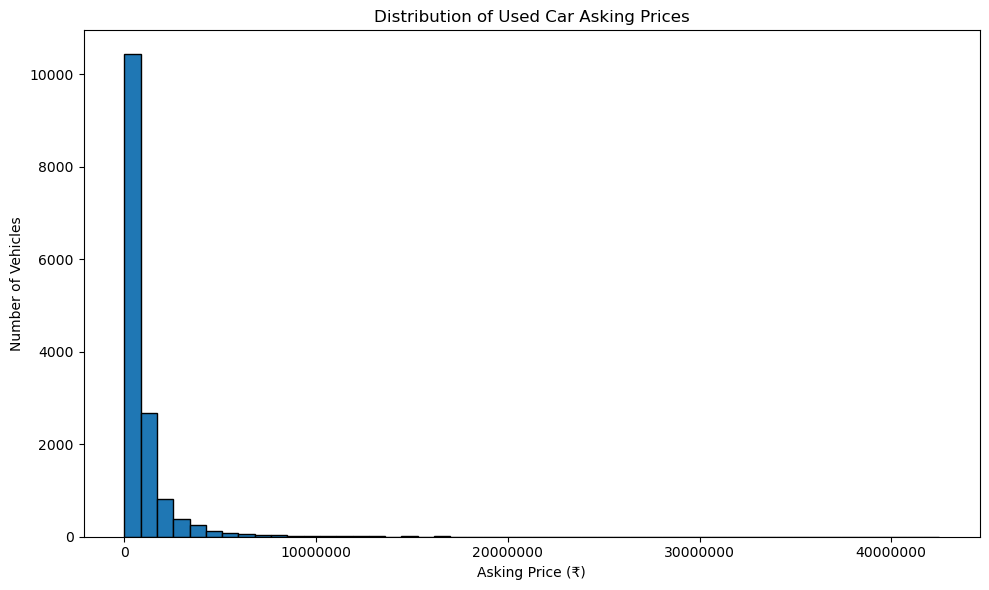

In [179]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["AskPrice"].dropna(),
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Used Car Asking Prices")
plt.xlabel("Asking Price (₹)")
plt.ylabel("Number of Vehicles")

plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

# Interpretation: Distribution of Asking Prices

The histogram indicates that vehicle asking prices are positively skewed, with most listings concentrated within the lower price ranges and a smaller number of vehicles listed at substantially higher prices. This suggests that the dataset contains a wide variation in vehicle prices. The extreme values may represent luxury and premium vehicles rather than incorrect observations. Therefore, high-priced listings should not automatically be removed during data cleaning.

# Visualisation 2: Box Plot of Vehicle Asking Prices

A box plot is used to examine the spread and variability of vehicle asking prices. It displays the median, quartiles and potential outliers.

This visualisation helps identify unusually high or low asking prices. However, potential outliers will not automatically be removed because some may represent legitimate luxury vehicles.

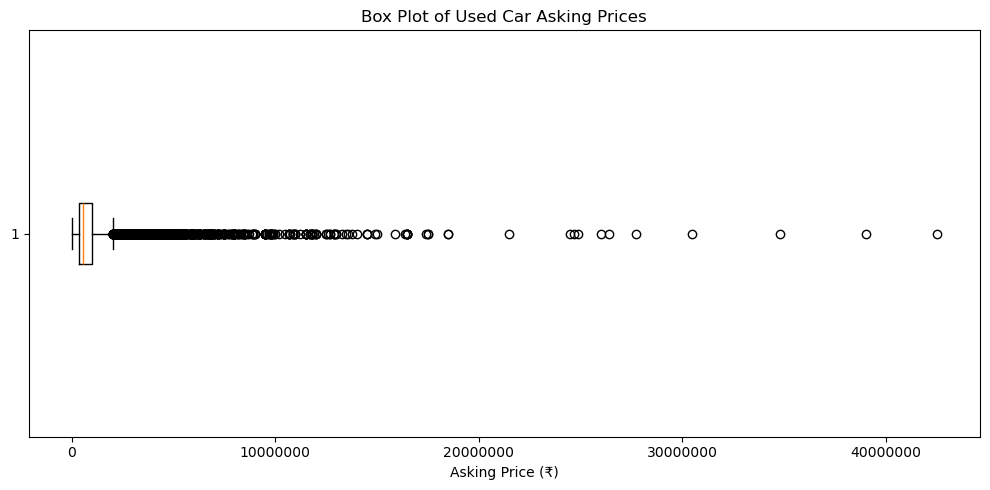

In [180]:
plt.figure(figsize=(10, 5))

plt.boxplot(
    df["AskPrice"].dropna(),
    vert=False
)

plt.title("Box Plot of Used Car Asking Prices")
plt.xlabel("Asking Price (₹)")

plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

# Interpretation: Box Plot of Asking Prices

The box plot identifies several high-priced observations beyond the upper whisker, indicating the presence of statistical outliers. These observations are consistent with the positively skewed distribution observed in the histogram. Since the dataset includes vehicles from different market segments, some extreme asking prices may be legitimate. These observations will therefore be retained unless further investigation establishes that they are inaccurate or invalid.

# Visualisation 3: Top 10 Most Frequently Listed Vehicle Brands

A horizontal bar chart is used to display the ten most frequently occurring vehicle brands.

This visualisation helps identify which manufacturers are most represented in the dataset and provides an overview of the distribution of vehicle brands.

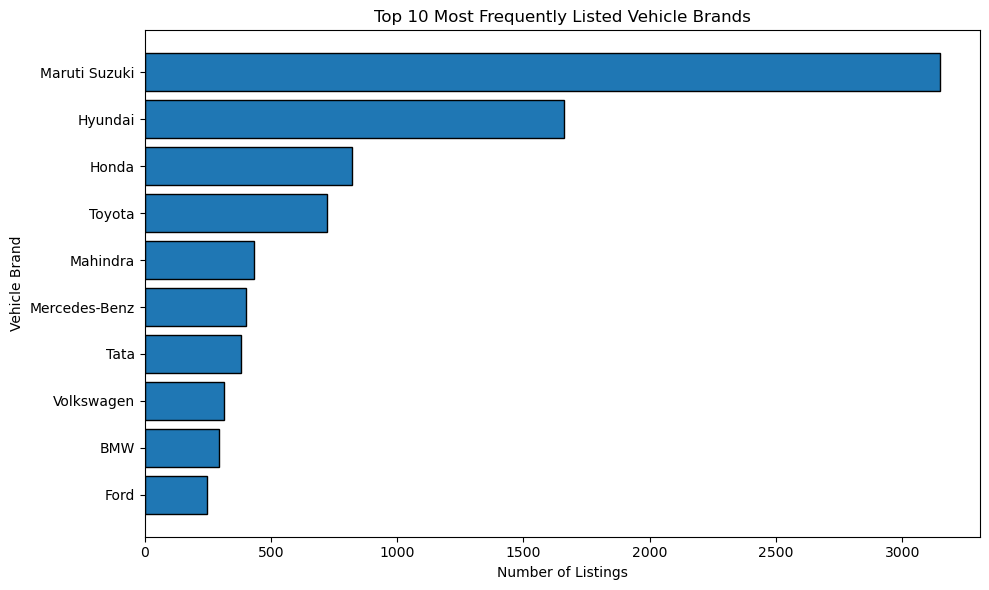

In [181]:
brand_counts = (
    df.loc[
        df["Brand"].notna() &
        (df["Brand"] != "Unknown"),
        "Brand"
    ]
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))

plt.barh(
    brand_counts.index,
    brand_counts.values,
    edgecolor="black"
)

plt.title("Top 10 Most Frequently Listed Vehicle Brands")
plt.xlabel("Number of Listings")
plt.ylabel("Vehicle Brand")

plt.tight_layout()
plt.show()

# Interpretation: Distribution of Vehicle Brands

Maruti Suzuki is the most frequently represented vehicle brand in the dataset, followed by Hyundai, Honda and Toyota. This indicates that the dataset contains a higher concentration of listings from these manufacturers. Premium vehicle brands such as BMW and Mercedes-Benz have fewer observations among the ten most frequently listed brands. The distribution suggests that the dataset is not evenly represented across vehicle manufacturers, which may influence the model's ability to predict prices for brands with fewer observations.

# Visualisation 4: Relationship Between Vehicle Mileage and Asking Price

A scatter plot is used to investigate the relationship between vehicle mileage and asking price.

Mileage is an important vehicle characteristic because the distance travelled may influence resale value. This visualisation helps identify possible patterns, relationships and unusual observations.

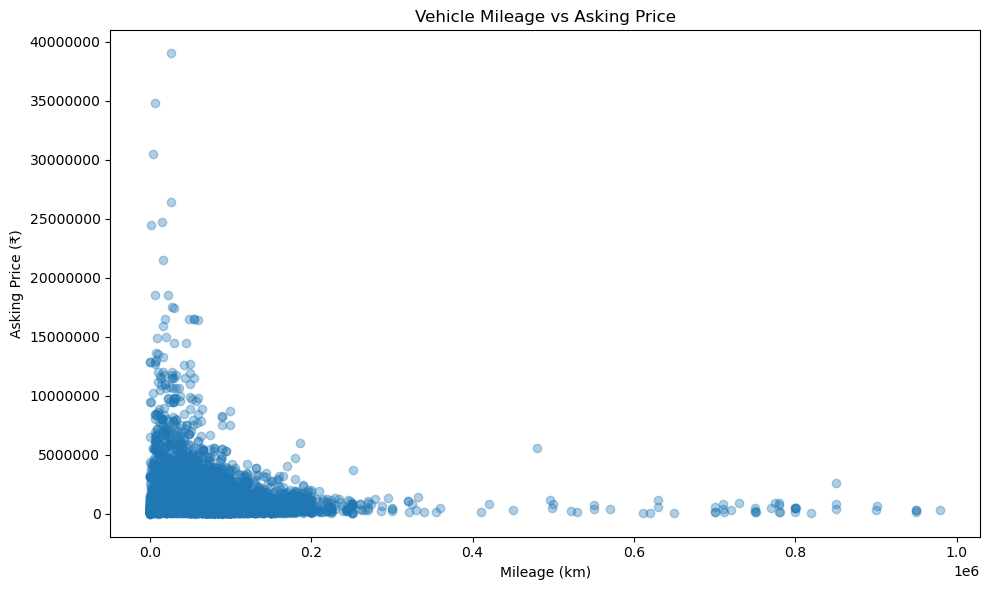

In [182]:
mileage_price = df[
    ["kmDriven", "AskPrice"]
].dropna()

plt.figure(figsize=(10, 6))

plt.scatter(
    mileage_price["kmDriven"],
    mileage_price["AskPrice"],
    alpha=0.35
)

plt.title("Vehicle Mileage vs Asking Price")
plt.xlabel("Mileage (km)")
plt.ylabel("Asking Price (₹)")

plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

# Interpretation: Vehicle Mileage and Asking Price

The scatter plot suggests a negative relationship between vehicle mileage and asking price. In general, vehicles with higher recorded mileage tend to have lower asking prices. However, the relationship is not perfectly linear, as other factors such as brand, model, year, transmission and vehicle condition may also influence asking prices. The concentration of observations at lower mileage values and the presence of extreme mileage values also indicate variation in the dataset.

# Visualisation 5: Asking Price by Transmission Type

A box plot is used to compare the distribution of asking prices between automatic and manual vehicles.

The comparison examines differences in median asking prices, variability and potential extreme observations across the two transmission categories.

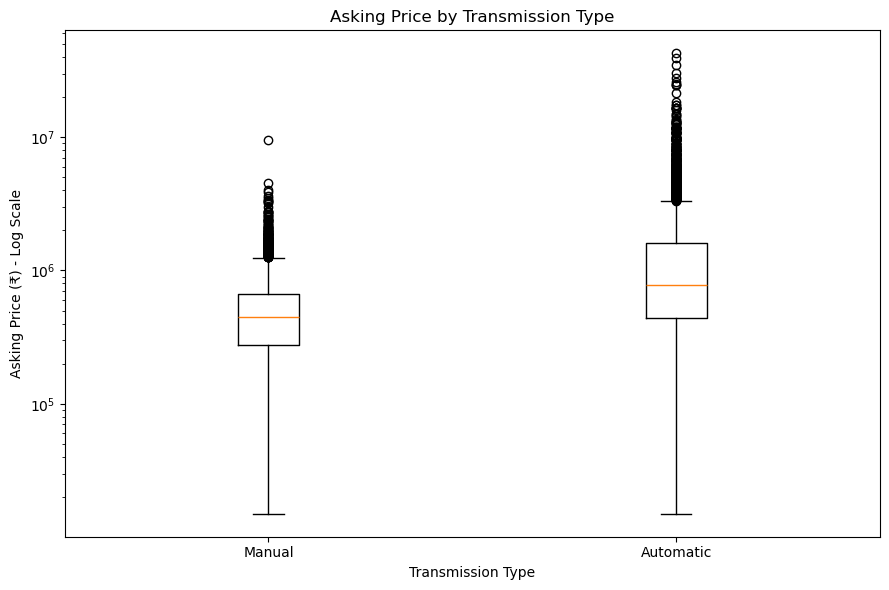

In [183]:
transmission_data = [
    df.loc[df["Transmission"] == "Manual", "AskPrice"].dropna(),
    df.loc[df["Transmission"] == "Automatic", "AskPrice"].dropna()
]

plt.figure(figsize=(9, 6))

plt.boxplot(
    transmission_data,
    tick_labels=["Manual", "Automatic"]
)

plt.yscale("log")

plt.title("Asking Price by Transmission Type")
plt.xlabel("Transmission Type")
plt.ylabel("Asking Price (₹) - Log Scale")

plt.tight_layout()
plt.show()

# Interpretation: Asking Price by Transmission Type

The box plot suggests that automatic vehicles generally have higher median asking prices and greater price variability than manual vehicles. However, both transmission categories contain high-priced outliers. This suggests that transmission type may be associated with differences in asking prices, although the relationship may also be influenced by other vehicle characteristics.

# Visualisation 6: Missing Values Across Dataset Variables

A bar chart is used to illustrate the percentage of missing values across the dataset variables.

This visualisation provides a comparison of data completeness and identifies variables that require attention during preprocessing.

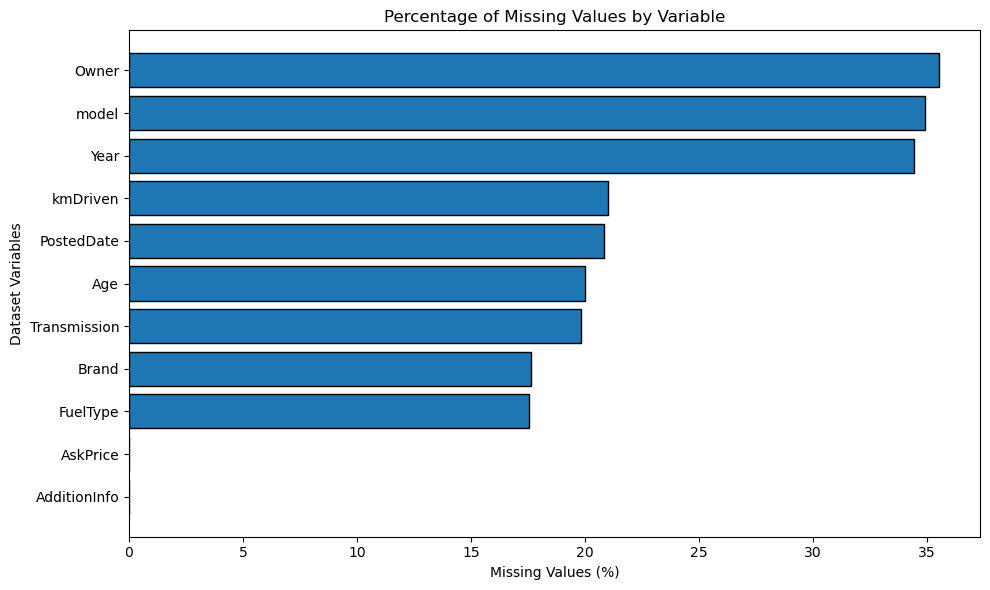

In [184]:
missing_percentages = (
    df.isna().mean() * 100
).sort_values()

plt.figure(figsize=(10, 6))

plt.barh(
    missing_percentages.index,
    missing_percentages.values,
    edgecolor="black"
)

plt.title("Percentage of Missing Values by Variable")
plt.xlabel("Missing Values (%)")
plt.ylabel("Dataset Variables")

plt.tight_layout()
plt.show()

# Interpretation: Missing Values

The missing-value analysis indicates that several predictor variables contain substantial missing data. Owner and model have the highest proportions of missing observations, followed by mileage, posting date, age, transmission, brand, year and fuel type. The target variable, AskPrice, contains no missing values. Since removing all incomplete observations would result in a considerable loss of data, missing predictor values will be handled through appropriate imputation techniques during preprocessing.

# Exploratory Data Analysis (EDA): Final Summary

The exploratory data analysis was conducted to understand the structure, distribution and quality of the used-car dataset before developing machine learning models.

The original dataset contained 24,575 records and 11 columns. After identifying and removing exact duplicate records, the working dataset contained 14,988 records and 11 columns.

### Key Findings

**1. Duplicate Records**

The initial investigation identified 9,587 exact duplicate records. These were removed to prevent repeated observations from unnecessarily influencing the analysis. A subsequent check confirmed that no exact duplicate records remain.

**2. Asking Price Distribution**

The `AskPrice` variable was converted into numerical format. The mean asking price was approximately ₹1,022,982, while the median was ₹580,000. This difference indicates a positively skewed distribution.

The highest recorded asking price was ₹42,500,000. Several high-priced observations belonged to luxury vehicle brands, including Rolls-Royce, Lamborghini and Mercedes-Benz. These observations were retained because high asking prices do not automatically indicate incorrect data.

**3. Categorical Variables**

The categorical-variable assessment identified 40 unique brands, 402 unique vehicle models, two transmission categories, two ownership categories and five fuel-type categories.

Formatting inconsistencies were corrected where appropriate. Four records incorrectly categorised as `Toyota Land` were reclassified as `Toyota` after examining their associated vehicle models.

**4. Missing Values**

Several predictor variables contain missing observations. The highest missing-value percentages were found in `Owner` (35.56%) and `model` (34.91%). The target variable, `AskPrice`, contains no missing values.

The decision was made to retain records with incomplete predictor information and handle missing values during the preprocessing stage.

**5. Numerical Variables**

The `kmDriven` variable was converted from text to numerical format. The analysis identified zero-mileage observations and unusually high mileage values, which were retained pending further assessment.

The `Year` variable contained 2,562 records with the invalid placeholder value 9999. These were converted to missing values. Additional implausible manufacturing years were investigated and corrected.

The relationship between `Year` and `Age` was also examined. A perfect negative correlation of -1.00 was identified after correcting invalid observations. Verification confirmed that all 8,259 records containing both variables followed the relationship `Age = 2024 - Year`.

Consequently, `Year` will be retained as a predictor, while `Age` will be excluded from the initial model because the two variables contain redundant information.

### Conclusion

The EDA identified several data-quality issues that required attention, including duplicate records, missing values, inconsistent categorical entries, invalid manufacturing years and unusually high numerical observations.

The dataset now contains 14,988 records, no exact duplicates and no missing target values. It is ready for the next stage of preparation, where appropriate feature selection, missing-value imputation and categorical encoding will be performed before model development.

### Preparation of Features and Target Variable

Following the completion of exploratory data analysis, the next stage involves preparing the dataset for machine learning.

The objective is to identify the independent variables that will be used to predict vehicle asking prices and separate them from the target variable.

The `Age`, `PostedDate` and `AdditionInfo` variables will initially be excluded. `Age` contains information already represented by `Year`, while `PostedDate` and `AdditionInfo` will be considered for future feature-engineering experiments.

The remaining vehicle characteristics will form the initial feature matrix, while `AskPrice` will serve as the target variable.

In [185]:
features = [
    "Brand",
    "model",
    "Year",
    "kmDriven",
    "Transmission",
    "Owner",
    "FuelType"
]

X = df[features].copy()
y = df["AskPrice"].copy()

print("Feature matrix shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget summary:")
print(y.describe())

Feature matrix shape: (14988, 7)
Target variable shape: (14988,)

Feature columns:
['Brand', 'model', 'Year', 'kmDriven', 'Transmission', 'Owner', 'FuelType']

Target summary:
count           14988.0
mean      996884.795703
std      1586834.596681
min             15000.0
25%            349000.0
50%            570000.0
75%           1025000.0
max          42500000.0
Name: AskPrice, dtype: Float64


# Feature Matrix and Target Variable Preparation

The initial modelling dataset was successfully prepared by separating the independent variables from the target variable.

The feature matrix (`X`) contains 14,988 observations and seven predictor variables: Brand, model, Year, kmDriven, Transmission, Owner and FuelType.

The target variable (`y`) contains 14,988 asking-price observations.

The descriptive statistics indicate a mean asking price of approximately ₹996,885 and a median of ₹570,000. The difference between these values confirms that the target variable has a positively skewed distribution.

The prepared feature matrix and target variable will be used in the subsequent preprocessing and model development stages.

# Splitting the Dataset into Training and Testing Sets

The dataset will be divided into training and testing subsets before model development.

The training dataset will be used to fit the machine learning models, allowing them to learn relationships between vehicle characteristics and asking prices.

The testing dataset will be kept separate and used to evaluate the predictive performance of the trained models on unseen observations.

An 80:20 split will be applied, with 80% of the observations allocated to training and 20% allocated to testing. A random state will be specified to ensure reproducibility of the results.

In [186]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (11990, 7)
Testing features: (2998, 7)
Training target: (11990,)
Testing target: (2998,)


## Model Development

The next stage involves developing machine learning models to predict used vehicle asking prices. The dataset has been divided into training and testing sets. The training set will be used to train the models, while the testing set will be reserved for evaluating how well the models perform on unseen data.

A preprocessing pipeline will be used to handle missing values and convert categorical variables into numerical representations.

In [187]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Identifying Numerical and Categorical Features

The dataset contains both numerical and categorical variables. Numerical variables require missing-value treatment, while categorical variables need to be converted into numerical representations before they can be used by machine learning algorithms.

The features will therefore be separated into numerical and categorical groups to allow appropriate preprocessing.

In [188]:
numerical_features = ["Year", "kmDriven"]

categorical_features = [
    "Brand",
    "model",
    "Transmission",
    "Owner",
    "FuelType"
]

## Data Preprocessing

Missing numerical values will be replaced using the median, which is less sensitive to extreme values than the mean. Missing categorical values will be replaced using the most frequent category.

One-hot encoding will convert categorical variables into numerical columns. This allows the machine learning models to process vehicle brands, models, transmission types, ownership categories and fuel types.

In [189]:
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

## Model 1: Linear Regression

Linear Regression will be used as the baseline model. It attempts to predict vehicle asking prices by estimating the relationship between the input features and the target variable.

Its performance will provide a starting point against which more complex models can be compared.

In [190]:
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [191]:
y_pred_linear = linear_model.predict(X_test)

mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Results")
print("MAE:", mae_linear)
print("RMSE:", rmse_linear)
print("R²:", r2_linear)

Linear Regression Results
MAE: 492754.9650725786
RMSE: 1349118.8573785634
R²: 0.37242645396129703


## Model 2: Random Forest Regression

Random Forest Regression is an ensemble learning algorithm that combines predictions from multiple decision trees. Each tree learns patterns from the training data, and their predictions are combined to produce a final estimate.

This model is selected to determine whether a non-linear algorithm can predict used vehicle asking prices more accurately than the Linear Regression baseline.

In [192]:
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=150,
        random_state=42,
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [193]:
y_pred_rf = random_forest_model.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R²:", r2_rf)

Random Forest Results
MAE: 490791.52803660487
RMSE: 1394348.9364959195
R²: 0.3296414657272422


In [194]:
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae_linear, mae_rf],
    "RMSE": [rmse_linear, rmse_rf],
    "R2": [r2_linear, r2_rf]
})

model_comparison

,Model,MAE,RMSE,R2
0,Linear Regression,492754.965073,1.349119e+06,0.372426
1,Random Forest,490791.528037,1.394349e+06,0.329641


## Model 3: Random Forest with Log-Transformed Target

The target variable, AskPrice, has a positively skewed distribution, with a small number of vehicles having substantially higher asking prices. A logarithmic transformation will be applied to reduce the influence of extreme values during model training.

The predictions will subsequently be converted back to the original price scale to allow comparison using the same evaluation metrics as the previous models.

In [195]:
from sklearn.compose import TransformedTargetRegressor

log_rf_model = TransformedTargetRegressor(
    regressor=Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=150,
            random_state=42,
            min_samples_leaf=2,
            n_jobs=-1
        ))
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

log_rf_model.fit(X_train, y_train)

,regressor,Pipeline(step...m_state=42))])
,transformer,None
,func,<ufunc 'log1p'>
,inverse_func,<ufunc 'expm1'>
,check_inverse,True
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False


In [196]:
y_pred_log_rf = log_rf_model.predict(X_test)

mae_log_rf = mean_absolute_error(y_test, y_pred_log_rf)
rmse_log_rf = np.sqrt(mean_squared_error(y_test, y_pred_log_rf))
r2_log_rf = r2_score(y_test, y_pred_log_rf)

print("Log-Transformed Random Forest Results")
print("MAE:", mae_log_rf)
print("RMSE:", rmse_log_rf)
print("R²:", r2_log_rf)

Log-Transformed Random Forest Results
MAE: 452416.87773120316
RMSE: 1427601.474258842
R²: 0.2972866913038462


In [197]:
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Log-Transformed Random Forest"
    ],
    "MAE": [
        mae_linear,
        mae_rf,
        mae_log_rf
    ],
    "RMSE": [
        rmse_linear,
        rmse_rf,
        rmse_log_rf
    ],
    "R2": [
        r2_linear,
        r2_rf,
        r2_log_rf
    ]
})

model_comparison.sort_values(by="MAE")

,Model,MAE,RMSE,R2
2,Log-Transformed Random Forest,452416.877731,1.427601e+06,0.297287
1,Random Forest,490791.528037,1.394349e+06,0.329641
0,Linear Regression,492754.965073,1.349119e+06,0.372426


## Model 4: Gradient Boosting Regression

Gradient Boosting Regression is an ensemble learning technique that builds decision trees sequentially. Each new tree attempts to improve the predictions by reducing errors made by the previous trees.

The model will be evaluated against the existing regression models to determine whether it provides better predictive performance.

In [198]:
from sklearn.ensemble import GradientBoostingRegressor

gradient_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gradient_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [199]:
y_pred_gb = gradient_model.predict(X_test)

mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting Results")
print("MAE:", mae_gb)
print("RMSE:", rmse_gb)
print("R²:", r2_gb)

Gradient Boosting Results
MAE: 533019.8855628244
RMSE: 1385616.6890317483
R²: 0.3380115467842709


In [200]:
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Log-Transformed Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mae_linear, mae_rf, mae_log_rf, mae_gb
    ],
    "RMSE": [
        rmse_linear, rmse_rf, rmse_log_rf, rmse_gb
    ],
    "R2": [
        r2_linear, r2_rf, r2_log_rf, r2_gb
    ]
})

model_comparison.sort_values(by="MAE")

,Model,MAE,RMSE,R2
2,Log-Transformed Random Forest,452416.877731,1.427601e+06,0.297287
1,Random Forest,490791.528037,1.394349e+06,0.329641
0,Linear Regression,492754.965073,1.349119e+06,0.372426
3,Gradient Boosting,533019.885563,1.385617e+06,0.338012


## Model Evaluation and Selection

Four regression models were developed and evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and the coefficient of determination (R²).

The Linear Regression model achieved the highest R² score of 0.3724 and the lowest RMSE of approximately ₹1,349,119. The Log-Transformed Random Forest model achieved the lowest MAE of approximately ₹452,417, indicating a lower average absolute prediction error.

However, Linear Regression demonstrated stronger overall performance in terms of RMSE and R². It was therefore selected as the preferred model for further evaluation. The results also indicate that predicting used vehicle asking prices remains challenging due to the variation in vehicle characteristics and the presence of extreme asking prices.

## Actual vs Predicted Asking Prices

A scatter plot is used to compare the actual vehicle asking prices with the prices predicted by the selected Linear Regression model. A reference line represents perfect predictions. The closer the observations are to this line, the more accurate the predictions.

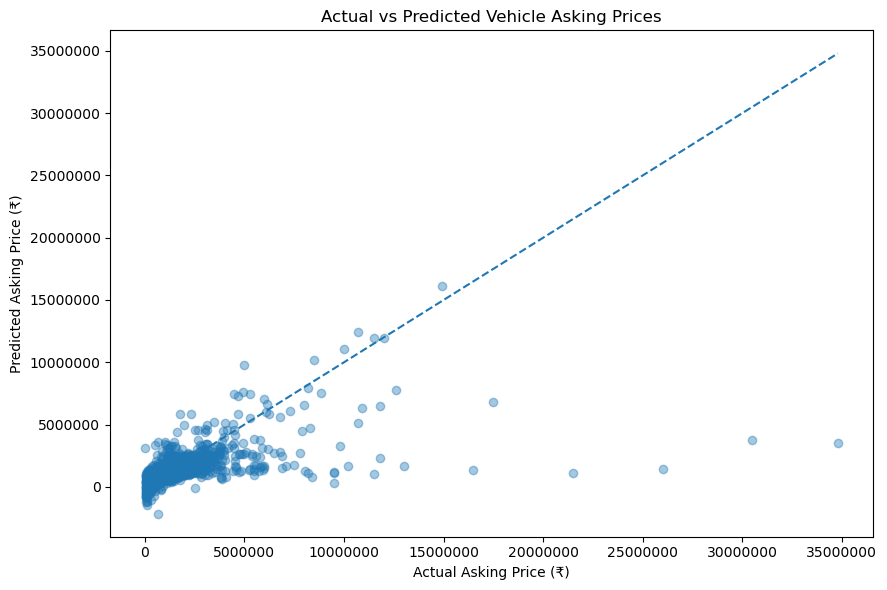

In [201]:
plt.figure(figsize=(9, 6))

plt.scatter(y_test, y_pred_linear, alpha=0.4)

max_price = max(y_test.max(), y_pred_linear.max())

plt.plot(
    [0, max_price],
    [0, max_price],
    linestyle="--"
)

plt.title("Actual vs Predicted Vehicle Asking Prices")
plt.xlabel("Actual Asking Price (₹)")
plt.ylabel("Predicted Asking Price (₹)")

plt.ticklabel_format(style="plain", axis="both")
plt.tight_layout()
plt.show()

## Interpretation: Actual vs Predicted Asking Prices

The scatter plot indicates that the Linear Regression model produces predictions that vary considerably from the actual vehicle asking prices. While some observations are relatively close to the reference line, several high-priced vehicles are substantially underestimated. This suggests that the model struggles to predict prices accurately for vehicles in the higher price segments. The results demonstrate that although the model captures some relationships between vehicle characteristics and asking prices, its overall predictive performance is limited.

In [202]:
import joblib




joblib.dump(linear_model, "used_car_price_model.pkl")


print("Model saved successfully.")

Model saved successfully.


In [203]:
import joblib
import os

saved_model = joblib.load("used_car_price_model.pkl")

test_predictions = saved_model.predict(X_test.head(5))

print("Model file exists:", os.path.exists("used_car_price_model.pkl"))
print("Model loaded successfully.")
print("Sample predictions:", test_predictions)

Model file exists: True
Model loaded successfully.
Sample predictions: [2084043.49934516  457555.66305105  218665.48783007 2554740.24448871
 3850318.71231371]


## Exporting the Cleaned Dataset

The cleaned dataset is exported into CSV format to preserve the results of the data cleaning and preparation process. This file provides a reusable version of the dataset for further analysis and allows the cleaned data to be accessed independently of the Jupyter Notebook.

In [204]:
df.to_csv("used_cars_cleaned.csv", index=False)

print("Cleaned dataset exported successfully.")
print("Dataset shape:", df.shape)

Cleaned dataset exported successfully.
Dataset shape: (14988, 11)


In [205]:
import os

print("File exists:", os.path.exists("used_cars_cleaned.csv"))

File exists: True


In [206]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset shape:")
print(df.shape)

print("\nFirst 5 rows:")
print(df.head().to_string())

print("\nData types:")
print(df.dtypes)

Column names:
['Brand', 'model', 'Year', 'Age', 'kmDriven', 'Transmission', 'Owner', 'FuelType', 'PostedDate', 'AdditionInfo', 'AskPrice']

Dataset shape:
(14988, 11)

First 5 rows:
           Brand  model    Year   Age  kmDriven Transmission   Owner FuelType PostedDate                                             AdditionInfo  AskPrice
0            NaN    NaN  2001.0  23.0   98000.0          NaN     NaN  Unknown     Nov-24  Honda City v teck in mint condition, valid genuine car,  195000.0
1         Toyota    NaN     NaN  15.0  190000.0       Manual     NaN   Diesel     Jul-24      Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, Diesel  375000.0
2     Volkswagen    NaN  2010.0   NaN      <NA>       Manual   first      NaN     Nov-24   Volkswagen Vento 2010-2013 Diesel Breeze, 2010, Diesel  184999.0
3            NaN  Swift  2017.0   7.0      <NA>       Manual  second  Unknown        NaN           Maruti Suzuki Swift 2017 Diesel Good Condition  565000.0
4  Maruti Suzuki    NaN  2019.0   5.0 

In [207]:
import os

print(os.listdir())

['.config', 'Music', 'Sales_Analysis.ipynb', '.zprofile.pysave', '.copilot', 'CAPSTONE EDA', '.DS_Store', 'used_cars_cleaned.csv', '.vscode-shared', '.CFUserTextEncoding', '.xonshrc', 'CAPSTONE EDA.py', '.zshrc', 'OneDrive', '.psql_history', 'Pictures', '.zprofile', 'exam_score_histogram.png', '.zsh_history', '.ipython', 'Desktop', 'Library', '.matplotlib', 'CAPSTONE EDA.ipynb', 'Zotero', '.pgadmin', 'CAPSTONE PROJECT', '.cups', 'PycharmProjects', 'Public', '.idlerc', '.tcshrc', '.anaconda', 'Movies', 'Applications', 'CAPSTONE EDA-Copy1.ipynb', '.Trash', 'Student_Performance_Analysis.ipynb', '.ipynb_checkpoints', '.jupyter', 'Documents', '.vscode', '.bash_profile', 'Downloads', '.python_history', '.continuum', 'used_car_price_model.pkl', '.zsh_sessions', '.conda', 'PyCharmMiscProject']
